In [10]:
#评估软件在8mer扩增长肽和随机蛋白肽上的预测偏好

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_enrichment_curve(df, hla_column='HLA', label_column='true_lab', score_column='pre', software_column='software',type=False):
    """
    横轴（X）：按软件预测得分 pre 从高到低排序后的肽占比（累积总肽数 / 总肽数）
    纵轴（Y）：对应累积真实肽占比（累积真实肽数 / 总真实肽数）。
    参考线：对角线（45°线）表示随机预测，没有富集。
    观察点：
    曲线越靠上方，说明软件越倾向给真实肽高分。
    曲线接近随机线，说明软件对真实肽没有区分能力。 """
    plt.figure(figsize=(6,4))

    df = df.sort_values(score_column, ascending=type).reset_index(drop=True)
    labels = df[label_column].to_numpy()
    cum_true = np.cumsum(labels)
    cum_total = np.arange(1, len(labels)+1) / len(labels)
    observed = cum_true / cum_true[-1]  # 累积真实肽占比
    plt.plot(cum_total, observed, linewidth=2)

    # 随机对角线
    plt.plot([0,1], [0,1], 'k--', label='Random')
    plt.xlabel('Cumulative fraction of peptides')
    plt.ylabel('Cumulative fraction of true peptides')
    plt.title('Enrichment Curve')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
#####按照不同的类型画图
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_enrichment_curve_type(df, label_column='true_lab', score_column='pre', software_column='software'):
    """
    横轴（X）：按软件预测得分 pre 从高到低排序后的肽占比（累积总肽数 / 总肽数）
    纵轴（Y）：对应累积真实肽占比（累积真实肽数 / 总真实肽数）。
    参考线：对角线（45°线）表示随机预测，没有富集。
    观察点：
    曲线越靠上方，说明软件越倾向给真实肽高分。
    曲线接近随机线，说明软件对真实肽没有区分能力。 """
    plt.figure(figsize=(6,5))
    typelist = df[software_column].unique()

    for Type in typelist:
        df_type = df[df[software_column] == Type].copy()

        if "LKMHCpan" in Type:
            df_type = df_type.sort_values(score_column, ascending=False).reset_index(drop=True)

            labels = df_type[label_column].to_numpy()
            cum_true = np.cumsum(labels)
            cum_total = np.arange(1, len(labels)+1) / len(labels)
            observed = cum_true / cum_true[-1]  # 累积真实肽占比
            plt.plot(cum_total, observed,label=Type, linewidth=2)
        else:
            df_type = df_type.sort_values(score_column, ascending=True).reset_index(drop=True)

            labels = df_type[label_column].to_numpy()
            cum_true = np.cumsum(labels)
            cum_total = np.arange(1, len(labels)+1) / len(labels)
            observed = cum_true / cum_true[-1]  # 累积真实肽占比
            plt.plot(cum_total, observed,label=Type, linewidth=2,linestyle='-.')            

    # 随机对角线
    plt.plot([0,1], [0,1], 'k:', label='Random')
    plt.xlabel('Cumulative fraction of peptides')
    plt.ylabel('Cumulative fraction of true peptides')
    plt.title('Enrichment Curve')
    plt.legend()
    plt.tight_layout()
    plt.savefig('plot_expand_fig_lk_netmhcpan4.1.svg')
    plt.show()

In [ ]:
lk_01="Table_8mer_expand_randome_lk_net_LKMHCpan_positive.tsv"
lk_02='Table_8mer_expand_nomotif_lk_net_LKMHCpan_positive.tsv'
lk_03="Table_8mer_expand_allanchor_lk_net_LKMHCpan_positive.tsv"
net_01="Table_8mer_expand_randome_lk_net_netMHCpan_pos.tsv"
net_02="Table_8mer_expand_nomotif_lk_net_netMHCpan_pos.tsv"
net_03="Table_8mer_expand_allanchor_lk_net_netMHCpan_pos.tsv"

In [16]:
def chang_format(filename,type):
    df_fit=pd.read_csv(filename,sep="\t") 
    df_fit['software']=type
    return df_fit

In [17]:
df_lk_01_fit=chang_format(lk_01,'LKMHCpan:URTEL')
df_lk_02_fit=chang_format(lk_02,'LKMHCpan:CNTEL-D')
df_lk_03_fit=chang_format(lk_03,'LKMHCpan:TAEL')

df_net_01_fit=chang_format(net_01,'netMHCpan4.1:URTEL')
df_net_02_fit=chang_format(net_02,'netMHCpan4.1:CNTEL-D')
df_net_03_fit=chang_format(net_03,'netMHCpan4.1:TAEL')


In [18]:
merged_df = pd.concat([df_lk_01_fit, df_lk_02_fit, df_lk_03_fit, df_net_01_fit, df_net_02_fit, df_net_03_fit], axis=0,ignore_index=True) # 重置索引
merged_df['software'].value_counts()

software
LKMHCpan:URTEL          424470
netMHCpan4.1:URTEL      424470
LKMHCpan:CNTEL-D        353725
LKMHCpan:TAEL           353725
netMHCpan4.1:CNTEL-D    353725
netMHCpan4.1:TAEL       353725
Name: count, dtype: int64

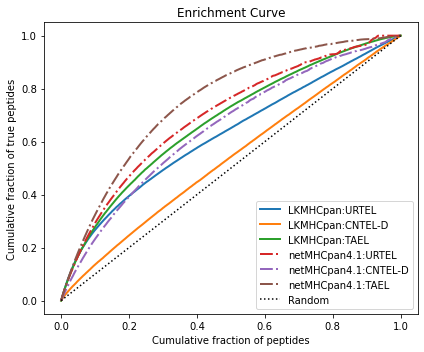

In [19]:
plot_enrichment_curve_type(merged_df)